In [3]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from scipy import stats
warnings.filterwarnings('ignore')

# Configuration des styles graphiques
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('deep')


In [6]:
# Chargement du dataset (assurez-vous que 'creditcard.csv' est dans le répertoire)
df = pd.read_csv("C://Users//DJEKONBE Aristote//Desktop//creditcard.csv",sep =",")

In [7]:
df

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
284802,172786.0,-11.881118,10.071785,-9.834783,-2.066656,-5.364473,-2.606837,-4.918215,7.305334,1.914428,...,0.213454,0.111864,1.014480,-0.509348,1.436807,0.250034,0.943651,0.823731,0.77,0
284803,172787.0,-0.732789,-0.055080,2.035030,-0.738589,0.868229,1.058415,0.024330,0.294869,0.584800,...,0.214205,0.924384,0.012463,-1.016226,-0.606624,-0.395255,0.068472,-0.053527,24.79,0
284804,172788.0,1.919565,-0.301254,-3.249640,-0.557828,2.630515,3.031260,-0.296827,0.708417,0.432454,...,0.232045,0.578229,-0.037501,0.640134,0.265745,-0.087371,0.004455,-0.026561,67.88,0
284805,172788.0,-0.240440,0.530483,0.702510,0.689799,-0.377961,0.623708,-0.686180,0.679145,0.392087,...,0.265245,0.800049,-0.163298,0.123205,-0.569159,0.546668,0.108821,0.104533,10.00,0


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

In [9]:
print(df.isnull().sum().max())  # Vérification rapide des valeurs manquantes

0


In [10]:
class_counts = df['Class'].value_counts()
class_ratio = df['Class'].value_counts(normalize=True) * 100

In [11]:
print(f"Transactions Légitimes (0) : {class_counts[0]} ({class_ratio[0]:.4f}%)")

Transactions Légitimes (0) : 284315 (99.8273%)


In [12]:
print(f"Transactions Frauduleuses (1) : {class_counts[1]} ({class_ratio[1]:.4f}% )")

Transactions Frauduleuses (1) : 492 (0.1727% )


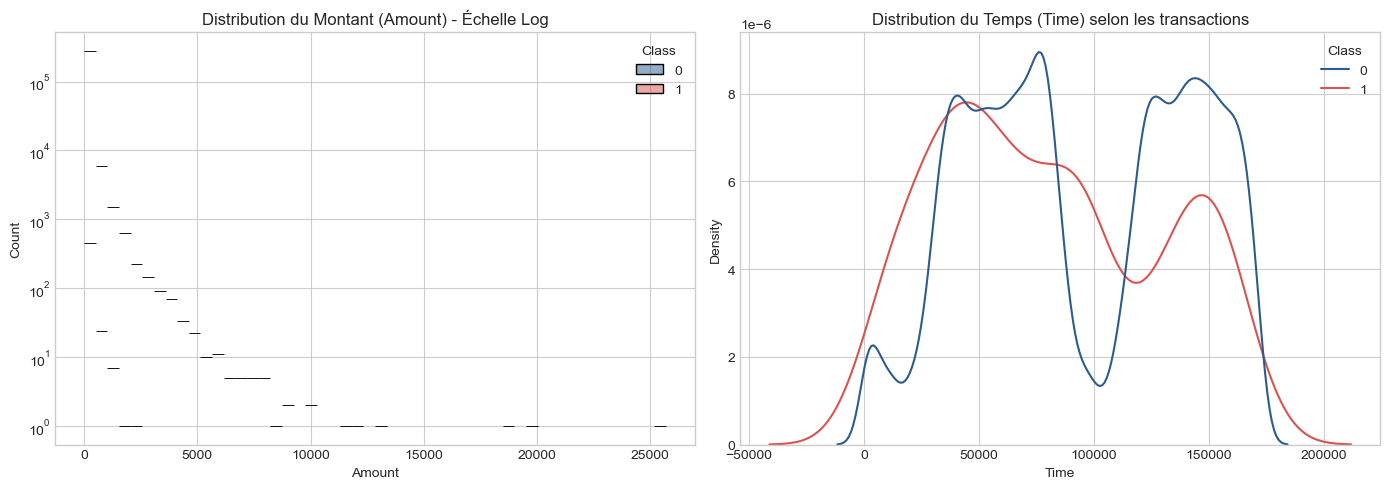

In [13]:
# Visualisation des distributions de 'Amount' et 'Time' selon la classe
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    data=df,
    x='Amount',
    hue='Class',
    bins=50,
    log_scale=(False, True),
    ax=axes[0],
    palette=['#2b5c8f', '#d9534f'],
)
axes[0].set_title(
    'Distribution du Montant (Amount) - Échelle Log', fontsize=12
)

sns.kdeplot(
    data=df,
    x='Time',
    hue='Class',
    common_norm=False,
    ax=axes[1],
    palette=['#2b5c8f', '#d9534f'],
)
axes[1].set_title(
    'Distribution du Temps (Time) selon les transactions', fontsize=12
)

plt.tight_layout()
plt.show()

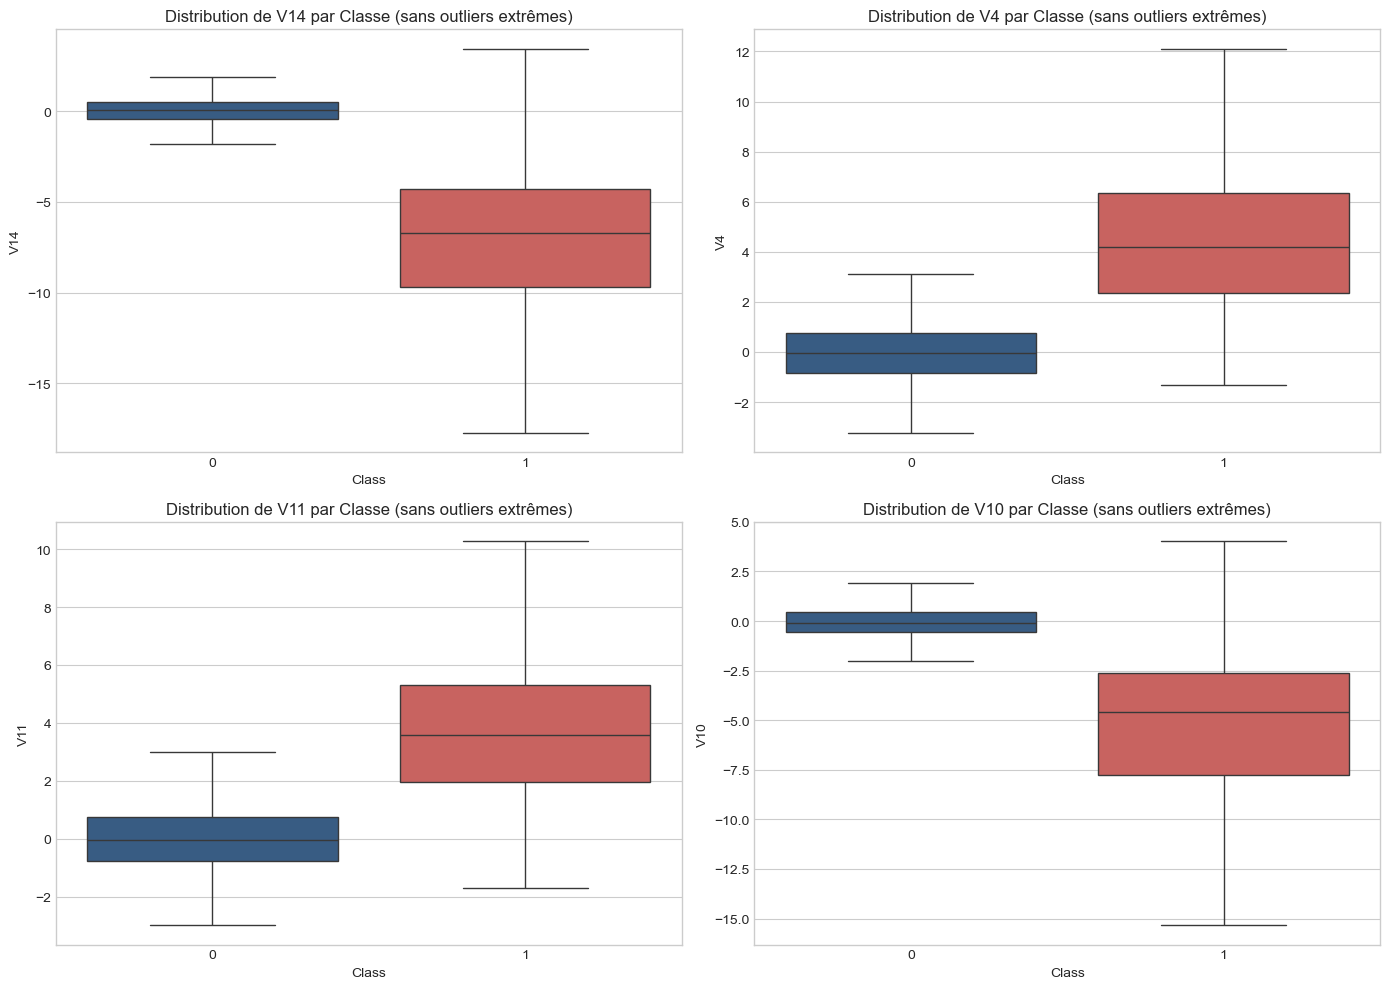

In [14]:
# Analyse univariée des principales variables PCA fortement corrélées à la fraude (ex: V14, V4, V11, V10)
key_features = ['V14', 'V4', 'V11', 'V10']

plt.figure(figsize=(14, 10))
for i, col in enumerate(key_features, 1):
  plt.subplot(2, 2, i)
  sns.boxplot(
      data=df, x='Class', y=col, palette=['#2b5c8f', '#d9534f'], showfliers=False
  )
  plt.title(f'Distribution de {col} par Classe (sans outliers extrêmes)')
plt.tight_layout()
plt.show()

# Analyse multivariées

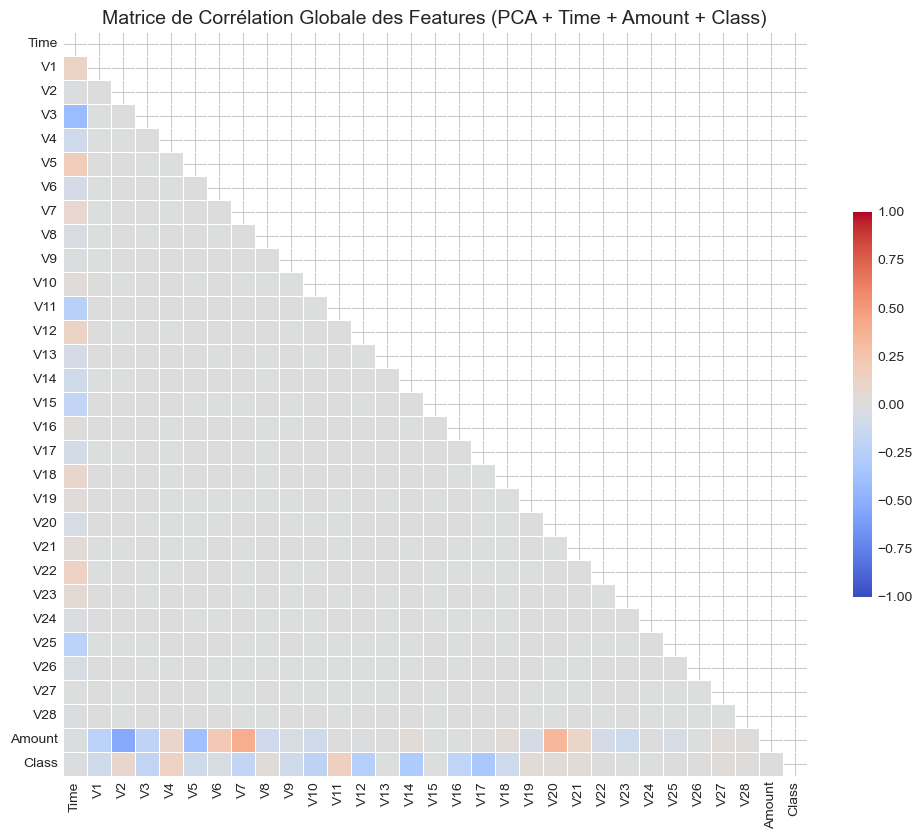

In [15]:
# Matrice de corrélation globale (échantillonnée pour la lisibilité si besoin)
plt.figure(figsize=(12, 10))
corr_matrix = df.corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(
    corr_matrix,
    mask=mask,
    cmap='coolwarm',
    vmax=1,
    vmin=-1,
    center=0,
    square=True,
    linewidths=0.5,
    cbar_kws={'shrink': 0.5},
)
plt.title(
    'Matrice de Corrélation Globale des Features (PCA + Time + Amount + Class)',
    fontsize=14,
)
plt.show()

In [16]:
# Focus sur les corrélations avec la variable cible 'Class'

class_corrs = corr_matrix['Class'].sort_values(ascending=False)
print('\n--- TOP CORRÉLATIONS AVEC LA FRAUDE (CLASS) ---')
print(class_corrs.head(10))
print(class_corrs.tail(5))


--- TOP CORRÉLATIONS AVEC LA FRAUDE (CLASS) ---
Class    1.000000
V11      0.154876
V4       0.133447
V2       0.091289
V21      0.040413
V19      0.034783
V20      0.020090
V8       0.019875
V27      0.017580
V28      0.009536
Name: Class, dtype: float64
V16   -0.196539
V10   -0.216883
V12   -0.260593
V14   -0.302544
V17   -0.326481
Name: Class, dtype: float64


In [17]:
# Échantillonnage pour fluidifier les graphiques interactifs (garder toutes les fraudes et un sous-ensemble de non-fraudes)

df_fraud = df[df['Class'] == 1]
df_normal = df[df['Class'] == 0].sample(n=5000, random_state=42)
df_sample = pd.concat([df_fraud, df_normal]).reset_index(drop=True)
df_sample['Class_Str'] = df_sample['Class'].map(
    {0: 'Légitime', 1: 'Frauduleux'}
)

In [18]:
df_fraud

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
541,406.0,-2.312227,1.951992,-1.609851,3.997906,-0.522188,-1.426545,-2.537387,1.391657,-2.770089,...,0.517232,-0.035049,-0.465211,0.320198,0.044519,0.177840,0.261145,-0.143276,0.00,1
623,472.0,-3.043541,-3.157307,1.088463,2.288644,1.359805,-1.064823,0.325574,-0.067794,-0.270953,...,0.661696,0.435477,1.375966,-0.293803,0.279798,-0.145362,-0.252773,0.035764,529.00,1
4920,4462.0,-2.303350,1.759247,-0.359745,2.330243,-0.821628,-0.075788,0.562320,-0.399147,-0.238253,...,-0.294166,-0.932391,0.172726,-0.087330,-0.156114,-0.542628,0.039566,-0.153029,239.93,1
6108,6986.0,-4.397974,1.358367,-2.592844,2.679787,-1.128131,-1.706536,-3.496197,-0.248778,-0.247768,...,0.573574,0.176968,-0.436207,-0.053502,0.252405,-0.657488,-0.827136,0.849573,59.00,1
6329,7519.0,1.234235,3.019740,-4.304597,4.732795,3.624201,-1.357746,1.713445,-0.496358,-1.282858,...,-0.379068,-0.704181,-0.656805,-1.632653,1.488901,0.566797,-0.010016,0.146793,1.00,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
279863,169142.0,-1.927883,1.125653,-4.518331,1.749293,-1.566487,-2.010494,-0.882850,0.697211,-2.064945,...,0.778584,-0.319189,0.639419,-0.294885,0.537503,0.788395,0.292680,0.147968,390.00,1
280143,169347.0,1.378559,1.289381,-5.004247,1.411850,0.442581,-1.326536,-1.413170,0.248525,-1.127396,...,0.370612,0.028234,-0.145640,-0.081049,0.521875,0.739467,0.389152,0.186637,0.76,1
280149,169351.0,-0.676143,1.126366,-2.213700,0.468308,-1.120541,-0.003346,-2.234739,1.210158,-0.652250,...,0.751826,0.834108,0.190944,0.032070,-0.739695,0.471111,0.385107,0.194361,77.89,1
281144,169966.0,-3.113832,0.585864,-5.399730,1.817092,-0.840618,-2.943548,-2.208002,1.058733,-1.632333,...,0.583276,-0.269209,-0.456108,-0.183659,-0.328168,0.606116,0.884876,-0.253700,245.00,1


In [19]:
df_normal

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
138028,82450.0,1.314539,0.590643,-0.666593,0.716564,0.301978,-1.125467,0.388881,-0.288390,-0.132137,...,-0.170307,-0.429655,-0.141341,-0.200195,0.639491,0.399476,-0.034321,0.031692,0.76,0
63099,50554.0,-0.798672,1.185093,0.904547,0.694584,0.219041,-0.319295,0.495236,0.139269,-0.760214,...,0.202287,0.578699,-0.092245,0.013723,-0.246466,-0.380057,-0.396030,-0.112901,4.18,0
73411,55125.0,-0.391128,-0.245540,1.122074,-1.308725,-0.639891,0.008678,-0.701304,-0.027315,-2.628854,...,-0.133485,0.117403,-0.191748,-0.488642,-0.309774,0.008100,0.163716,0.239582,15.00,0
164247,116572.0,-0.060302,1.065093,-0.987421,-0.029567,0.176376,-1.348539,0.775644,0.134843,-0.149734,...,0.355576,0.907570,-0.018454,-0.126269,-0.339923,-0.150285,-0.023634,0.042330,57.00,0
148999,90434.0,1.848433,0.373364,0.269272,3.866438,0.088062,0.970447,-0.721945,0.235983,0.683491,...,0.103563,0.620954,0.197077,0.692392,-0.206530,-0.021328,-0.019823,-0.042682,0.00,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
46348,42747.0,-0.590484,0.853099,1.416504,-0.421532,0.353362,-0.683382,0.670361,0.097574,-0.284073,...,-0.172126,-0.629355,0.009888,-0.018903,-0.447087,-0.054706,0.071186,0.130037,0.89,0
190577,128890.0,-0.650715,1.507848,-0.464356,-0.193506,0.840083,-0.179511,0.741093,-0.395269,0.360200,...,0.175713,0.736084,0.093480,0.673279,-1.428057,0.294175,-0.368839,0.203943,0.78,0
253493,156279.0,1.875080,1.094644,-1.737324,4.002882,1.091326,-0.323998,0.338522,0.008208,-1.257262,...,-0.397186,-1.175870,0.263150,-0.667589,-0.260184,-0.339979,-0.011355,0.004207,9.27,0
126871,78132.0,-3.120854,2.665293,0.960272,2.954251,-1.904986,2.888720,-3.553750,0.023727,0.169218,...,-1.166651,0.949434,-0.026779,-1.298061,0.508547,0.677465,0.210316,0.117562,0.00,0


In [20]:
df_sample

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V22,V23,V24,V25,V26,V27,V28,Amount,Class,Class_Str
0,406.0,-2.312227,1.951992,-1.609851,3.997906,-0.522188,-1.426545,-2.537387,1.391657,-2.770089,...,-0.035049,-0.465211,0.320198,0.044519,0.177840,0.261145,-0.143276,0.00,1,Frauduleux
1,472.0,-3.043541,-3.157307,1.088463,2.288644,1.359805,-1.064823,0.325574,-0.067794,-0.270953,...,0.435477,1.375966,-0.293803,0.279798,-0.145362,-0.252773,0.035764,529.00,1,Frauduleux
2,4462.0,-2.303350,1.759247,-0.359745,2.330243,-0.821628,-0.075788,0.562320,-0.399147,-0.238253,...,-0.932391,0.172726,-0.087330,-0.156114,-0.542628,0.039566,-0.153029,239.93,1,Frauduleux
3,6986.0,-4.397974,1.358367,-2.592844,2.679787,-1.128131,-1.706536,-3.496197,-0.248778,-0.247768,...,0.176968,-0.436207,-0.053502,0.252405,-0.657488,-0.827136,0.849573,59.00,1,Frauduleux
4,7519.0,1.234235,3.019740,-4.304597,4.732795,3.624201,-1.357746,1.713445,-0.496358,-1.282858,...,-0.704181,-0.656805,-1.632653,1.488901,0.566797,-0.010016,0.146793,1.00,1,Frauduleux
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5487,42747.0,-0.590484,0.853099,1.416504,-0.421532,0.353362,-0.683382,0.670361,0.097574,-0.284073,...,-0.629355,0.009888,-0.018903,-0.447087,-0.054706,0.071186,0.130037,0.89,0,Légitime
5488,128890.0,-0.650715,1.507848,-0.464356,-0.193506,0.840083,-0.179511,0.741093,-0.395269,0.360200,...,0.736084,0.093480,0.673279,-1.428057,0.294175,-0.368839,0.203943,0.78,0,Légitime
5489,156279.0,1.875080,1.094644,-1.737324,4.002882,1.091326,-0.323998,0.338522,0.008208,-1.257262,...,-1.175870,0.263150,-0.667589,-0.260184,-0.339979,-0.011355,0.004207,9.27,0,Légitime
5490,78132.0,-3.120854,2.665293,0.960272,2.954251,-1.904986,2.888720,-3.553750,0.023727,0.169218,...,0.949434,-0.026779,-1.298061,0.508547,0.677465,0.210316,0.117562,0.00,0,Légitime


In [21]:
df_sample['Class_Str']

0       Frauduleux
1       Frauduleux
2       Frauduleux
3       Frauduleux
4       Frauduleux
           ...    
5487      Légitime
5488      Légitime
5489      Légitime
5490      Légitime
5491      Légitime
Name: Class_Str, Length: 5492, dtype: object

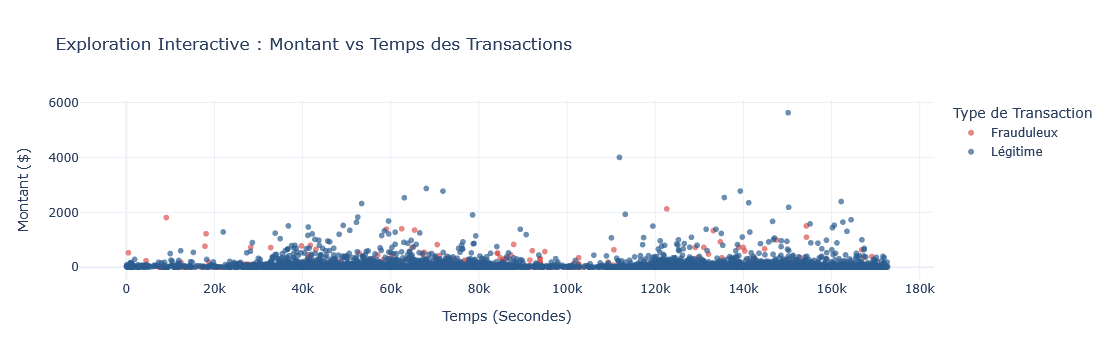

In [22]:
# Nuage de points interactif 2D : Time vs Amount coloré par Class

fig_scatter = px.scatter(
    df_sample,
    x='Time',
    y='Amount',
    color='Class_Str',
    color_discrete_map={'Légitime': '#2b5c8f', 'Frauduleux': '#d9534f'},
    opacity=0.7,
    title='Exploration Interactive : Montant vs Temps des Transactions',
    labels={'Time': 'Temps (Secondes)', 'Amount': 'Montant ($)'},
    hover_data=['V14', 'V4'],
)
fig_scatter.update_layout(
    template='plotly_white', legend_title='Type de Transaction'
)
fig_scatter.show()

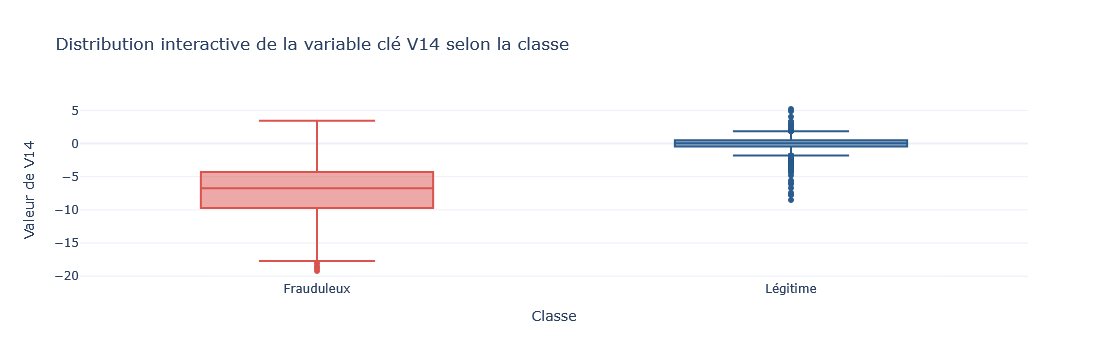

In [23]:
# Boxplot interactif pour comparer V14 selon la classe

fig_box = px.box(
    df_sample,
    x='Class_Str',
    y='V14',
    color='Class_Str',
    color_discrete_map={'Légitime': '#2b5c8f', 'Frauduleux': '#d9534f'},
    title='Distribution interactive de la variable clé V14 selon la classe',
    labels={'Class_Str': 'Classe', 'V14': 'Valeur de V14'},
)
fig_box.update_layout(template='plotly_white', showlegend=False)
fig_box.show()

In [25]:
print(
    '1. Déséquilibre Extrême : La classe cible est extrêmement déséquilibrée'
    f' (~{class_ratio[1]:.3f}% de fraudes). L’utilisation de l’Accuracy seule'
    ' est à proscrire ; privilégier l’AUC-ROC, l’AUPRC et le F1-Score.'
)

1. Déséquilibre Extrême : La classe cible est extrêmement déséquilibrée (~0.173% de fraudes). L’utilisation de l’Accuracy seule est à proscrire ; privilégier l’AUC-ROC, l’AUPRC et le F1-Score.


In [26]:
print(
    '2. Patterns Temporels et Monétaires : Le montant des fraudes tend à se'
    ' concentrer sur des valeurs plus faibles, et la variable Time montre des'
    ' cyclicité comportementales (périodes creuses vs pleines).'
)

2. Patterns Temporels et Monétaires : Le montant des fraudes tend à se concentrer sur des valeurs plus faibles, et la variable Time montre des cyclicité comportementales (périodes creuses vs pleines).


In [27]:
print(
    '3. Impact des Composantes PCA : Des variables comme V14, V4, V11 et V12'
    ' affichent des distributions radicalement différentes entre transactions'
    ' normales et frauduleuses, ce qui en fait les prédicteurs les plus'
    ' puissants pour les futurs modèles de Machine Learning (arbres de'
    ' décision / XGBoost).'
)

3. Impact des Composantes PCA : Des variables comme V14, V4, V11 et V12 affichent des distributions radicalement différentes entre transactions normales et frauduleuses, ce qui en fait les prédicteurs les plus puissants pour les futurs modèles de Machine Learning (arbres de décision / XGBoost).


# Interpréter cette analyse exploratoire (EDA) permet de comprendre la structure des données, d'identifier les pièges statistiques et de préparer le terrain pour les futurs modèles de Machine Learning.
# 1. Le déséquilibre critique des classes (Class Imbalance)

# Le constat majeur de l'audit initial est que les transactions frauduleuses représentent une infime minorité (environ 0,17 % du total).

    # Conséquence pour l'analyse : Un modèle naïf qui prédirait "toutes les transactions sont légitimes" obtiendrait une accuracy de 99,83 % tout en étant totalement inutile.

    # Conséquence pour la suite : Il faudra impérativement abandonner l'accuracy au profit de métriques adaptées au déséquilibre : l'AUPRC (Area Under the Precision-Recall Curve), le F1-Score et le Recall (pour rater le moins de fraudes possible).

# 2. Les enseignements univariés (Amount, Time et PCA)

    # Le Montant (Amount) : La distribution fortement asymétrique (skewed) montre que la grande majorité des fraudes se concentre sur des montants relativement faibles. Les fraudeurs évitent souvent les montants trop élevés pour ne pas déclencher des alertes automatiques immédiates.

    # Le Temps (Time) : Les variations temporelles indiquent des cycles d'activité (jours/nuits, heures de pointe). La fraude peut présenter des pics à des heures spécifiques où la surveillance humaine est plus faible.

    # Les variables PCA (V14, V4, V11, etc.) : Étant donné que les variables d'origine ont été anonymisées par une analyse en composantes principales, ces boîtes à moustaches révèlent que certaines composantes (notamment V14 et V4) ont des médianes et des quartiles radicalement décalés entre la classe 0 et la classe 1. Ce sont ces variables qui porteront l'essentiel du signal prédictif.

# 3. Les relations multivariées

    # La matrice de corrélation globale montre généralement que les variables PCA sont orthogonales entre elles (corrélation proche de 0), ce qui est la propriété mathématique normale d'une ACP.

    # Cependant, les corrélations ciblées avec la colonne Class mettent en évidence quelles composantes principales influencent le plus le risque de fraude, guidant directement la sélection des features.

# 4. La valeur ajoutée des graphiques interactifs (Plotly)

    # Les nuages de points dynamiques permettent de repérer visuellement des clusters ou des zones de concentration de fraude. En survolant les points, on peut identifier des profils atypiques (outliers) combinant un montant particulier et des valeurs extrêmes sur les composantes principales.

    # Cela aide à comprendre si la fraude est linéaire (séparable par une simple droite/plan) ou si elle forme des îlots complexes nécessitant des modèles non linéaires.

# 5. Recommandations pratiques pour le Machine Learning

# Grâce à cette analyse, la stratégie de modélisation s'oriente naturellement vers :

    # L'ingénierie des caractéristiques (Feature Engineering) : Normaliser le Amount (via StandardScaler ou RobustScaler pour gérer les outliers) et transformer la variable Time (par exemple en heures de la journée ou jours de la semaine).

    # Le choix des algorithmes : Privilégier les algorithmes basés sur les arbres (Random Forest, XGBoost, LightGBM) qui gèrent bien les variables non linéaires, ou des approches de détection d'anomalies (Isolation Forest, One-Class SVM).

    # La gestion du déséquilibre : Utiliser des techniques de rééchantillonnage comme SMOTE (Synthetic Minority Over-sampling Technique) ou ajuster les poids des classes (class_weight='balanced') lors de l'entraînement.